In [1]:
#import

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

**Esquema do sistema e forças**

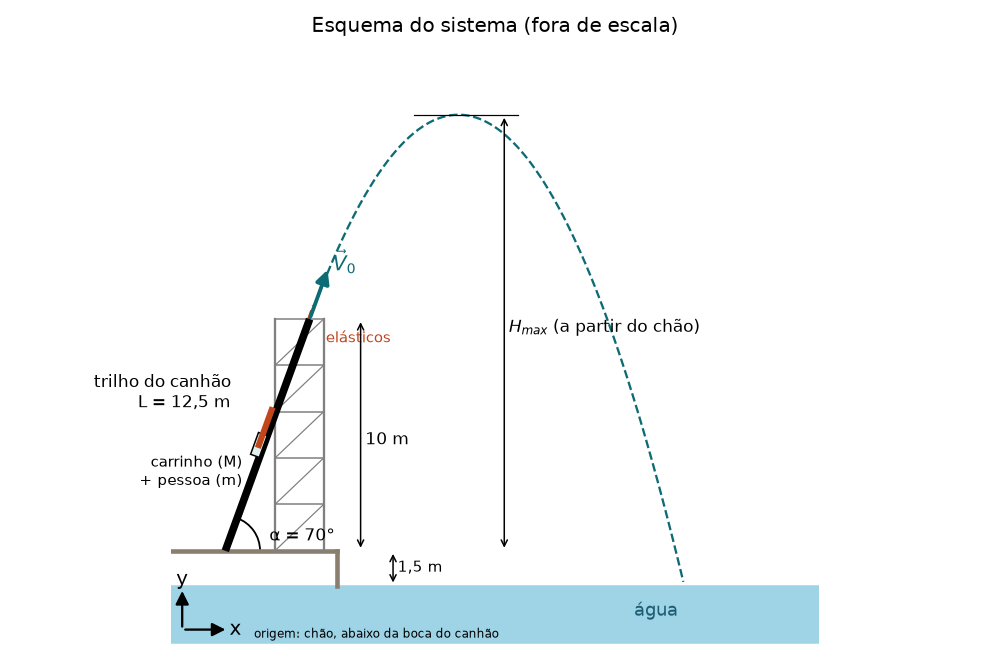

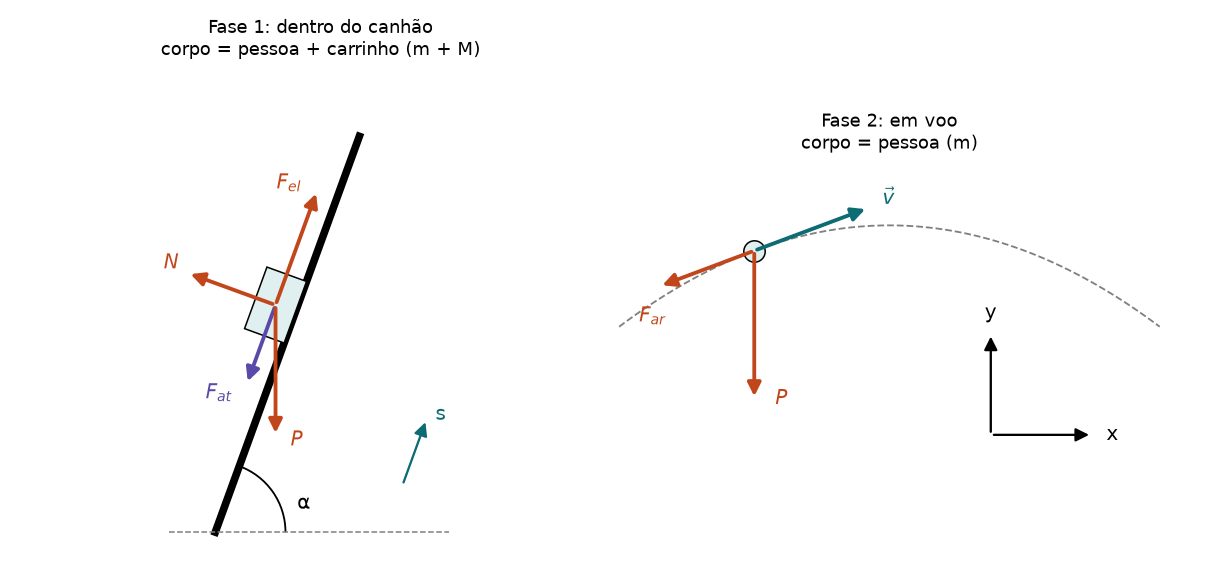

**Fase 1 - dentro do canhão** (pessoa + carrinho, massa $m + M$, eixo $s$ ao longo do trilho):
- $F_{el} = k \cdot (D_0 - s)$: força dos elásticos, puxa o carrinho trilho acima.
- $P = (m+M) \cdot g$: peso. Ao longo do trilho só atua a componente $P \, \text{sen}\,\alpha$.
- $N = P \cos\alpha$: normal do trilho (não há movimento perpendicular a ele).
- $F_{at} = \mu \cdot N$: atrito equivalente (representa todas as perdas do canhão), contra o movimento.

$$\frac{ds}{dt} = v \qquad \frac{dv}{dt} = \frac{k (D_0 - s) - (m+M)\, g \, \text{sen}\,\alpha - \mu (m+M)\, g \cos\alpha}{m+M}$$

**Fase 2 - em voo** (só a pessoa, massa $m$): no fim do trilho o carrinho é freado e a pessoa sai com velocidade $V_0$.
- $P = m \cdot g$: peso, para baixo.
- $F_{ar} = \frac{1}{2} \rho \, C_d \, A \, v^2$: resistência do ar, contrária à velocidade.

$$\frac{dx}{dt} = v_x \qquad \frac{dy}{dt} = v_y \qquad \frac{dv_x}{dt} = -\frac{F_{ar}}{m} \cdot \frac{v_x}{v} \qquad \frac{dv_y}{dt} = -\frac{F_{ar}}{m} \cdot \frac{v_y}{v} - g$$

In [2]:
#parametros

g = 9.81                  # gravidade [m/s2]
m = 85                    # massa da pessoa do salto do radar [kg]
M = 43                    # massa do carrinho [kg]
L = 12.5                  # comprimento do trilho [m]
alfa = np.radians(70)     # inclinacao do canhao [rad]
hboca = 10                # altura da boca do canhao [m]
yagua = -1.5              # nivel da agua em relacao ao chao [m]
rho = 1.2                 # densidade do ar [kg/m3]
Cd = 1.0                  # coeficiente de arrasto (estimativa)
A = 0.11                  # area frontal da pessoa em pe [m2] (estimativa)

# elastico: calculado com as aceleracoes da planilha da equipe (85 kg)
aini = 15.4               # aceleracao no inicio do trilho [m/s2]
afim = 1.7                # aceleracao no fim do trilho [m/s2]
Fini = (m + M) * (aini + g*np.sin(alfa))
Ffim = (m + M) * (afim + g*np.sin(alfa))
k = (Fini - Ffim) / L     # constante elastica [N/m]
D0 = Ffim/k + L           # alongamento inicial do elastico [m]

# dado medido no video
vradar = 49.5 / 3.6       # radar no salto de 85 kg, 49 a 50 km/h [m/s]

In [3]:
#modelo

def modelo_canhao(x, t, m, mu):
    s = x[0]
    v = x[1]
    Fel = k * (D0 - s)
    P = (m + M) * g
    N = P * np.cos(alfa)
    Fat = mu * N
    dsdt = v
    dvdt = (Fel - P*np.sin(alfa) - Fat) / (m + M)
    return [dsdt, dvdt]


def modelo_voo(x, t, m):
    vx = x[2]
    vy = x[3]
    v = np.sqrt(vx**2 + vy**2)
    Far = 0.5 * rho * Cd * A * v**2
    dxdt = vx
    dydt = vy
    dvxdt = -Far * (vx/v) / m
    dvydt = (-Far * (vy/v) - m*g) / m
    return [dxdt, dydt, dvxdt, dvydt]


def lancamento(m, mu):
    # fase 1: dentro do canhao, ate s = L
    dt = 0.001
    tempo = np.arange(0, 3+dt, dt)
    x_lista = odeint(modelo_canhao, [0, 0], tempo, args=(m, mu))
    i = 0
    while x_lista[i, 0] < L:
        i += 1
    V0 = x_lista[i, 1]

    # fase 2: voo, ate chegar na agua
    tempo = np.arange(0, 6+dt, dt)
    x0 = [0, hboca, V0*np.cos(alfa), V0*np.sin(alfa)]
    x_lista = odeint(modelo_voo, x0, tempo, args=(m,))
    tempo_voo = []
    y_voo = []
    j = 0
    while x_lista[j, 1] > yagua:
        tempo_voo.append(tempo[j])
        y_voo.append(x_lista[j, 1])
        j += 1
    return V0, tempo_voo, y_voo

In [4]:
#calibracao do atrito com o radar

mu_lista = np.arange(0, 0.35, 0.001)
erro_lista = []
for mu_teste in mu_lista:
    V0, tempo_voo, y_voo = lancamento(m, mu_teste)
    erro_lista.append(abs(V0 - vradar))

mu = mu_lista[np.argmin(erro_lista)]
print('mu =', round(mu, 3))

mu = 0.294


In [5]:
#simulacao do salto de 85 kg

V0, tempo_voo, y_voo = lancamento(m, mu)
print('V0 =', round(V0*3.6, 1), 'km/h')
print('Hmax =', round(max(y_voo), 2), 'm')
print('tempo de voo =', round(tempo_voo[-1], 2), 's')

V0 = 49.5 km/h
Hmax = 18.45 m
tempo de voo = 3.33 s


V0 medido no video = 49.3 km/h (radar: 49 a 50 km/h)
aceleracao vertical medida no video = 10.71 m/s2 (g = 9,81 m/s2)
Hmax: modelo = 18.45 m | video = 17.78 m | erro = 3.8 %
tempo de voo: modelo = 3.33 s | video = 3.08 s | erro = 8.2 %
erro medio da curva y(t) = 8.3 %


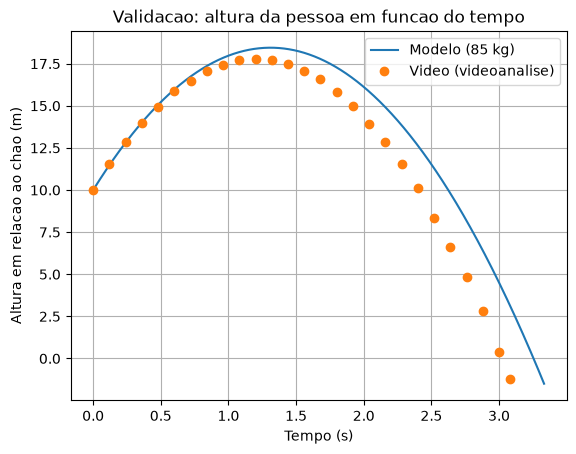

In [6]:
#validacao

# videoanalise do plano aberto com camera fixa (video 13:02 a 13:06), um ponto a cada 0,12 s
# t = 0 quando a pessoa sai do canhao (o cronometro do video comeca nesse quadro)
t_exp = [0, 0.12, 0.24, 0.36, 0.48, 0.6, 0.72, 0.84, 0.96, 1.08, 1.2, 1.32, 1.44, 1.56,
         1.68, 1.8, 1.92, 2.04, 2.16, 2.28, 2.4, 2.52, 2.64, 2.76, 2.88, 3.0, 3.08]     # [s]
ypx_exp = [481, 412, 356, 306, 264, 223, 196, 170, 154, 140, 138, 142, 152, 170,
           191, 224, 261, 307, 356, 414, 477, 554, 631, 709, 798, 905, 975]          # altura na imagem [pixel]

# escala: da boca do canhao (pixel 481) ate a agua (pixel 988) sao 10 + 1,5 = 11,5 m
ypx_boca = 481
ypx_agua = 988
escala = (ypx_agua - ypx_boca) / (hboca - yagua)         # [pixel/m]
y_exp = []
for ypx in ypx_exp:
    y_exp.append(hboca - (ypx - ypx_boca) / escala)       # altura em relacao ao chao [m]

# ajuste de uma parabola y = p0*t^2 + p1*t + p2 nos pontos do video
# p1 = velocidade vertical de saida [m/s] e -2*p0 = aceleracao vertical medida [m/s2]
# o narrador fala do Yianni (70 kg), mas a velocidade medida e a do radar, entao comparamos com o salto de 85 kg
p = np.polyfit(t_exp, y_exp, 2)
V0_exp = p[1] / np.sin(alfa)
g_exp = -2 * p[0]
print('V0 medido no video =', round(V0_exp*3.6, 1), 'km/h (radar: 49 a 50 km/h)')
print('aceleracao vertical medida no video =', round(g_exp, 2), 'm/s2 (g = 9,81 m/s2)')

# erros
y_mod = np.interp(t_exp, tempo_voo, y_voo)
erro_y = np.mean(np.abs(y_mod - np.array(y_exp))) / max(y_exp) * 100
erro_H = abs(max(y_voo) - max(y_exp)) / max(y_exp) * 100
erro_t = abs(tempo_voo[-1] - t_exp[-1]) / t_exp[-1] * 100
print('Hmax: modelo =', round(max(y_voo), 2), 'm | video =', round(max(y_exp), 2), 'm | erro =', round(erro_H, 1), '%')
print('tempo de voo: modelo =', round(tempo_voo[-1], 2), 's | video =', t_exp[-1], 's | erro =', round(erro_t, 1), '%')
print('erro medio da curva y(t) =', round(erro_y, 1), '%')

plt.plot(tempo_voo, y_voo, label='Modelo (85 kg)')
plt.plot(t_exp, y_exp, 'o', label='Video (videoanalise)')
plt.title('Validacao: altura da pessoa em funcao do tempo')
plt.xlabel('Tempo (s)')
plt.ylabel('Altura em relacao ao chao (m)')
plt.legend()
plt.grid()
plt.show()

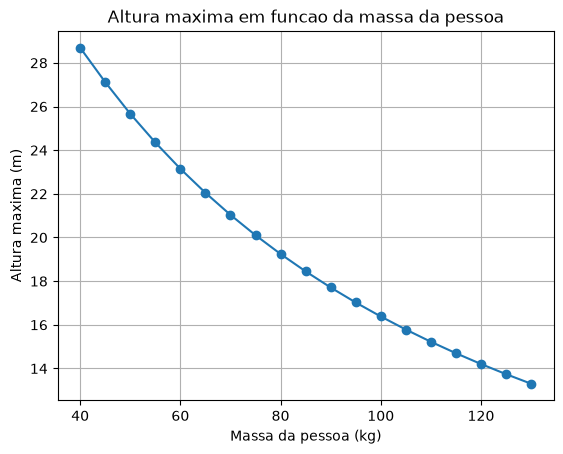

In [7]:
#grafico conclusivo

m_lista = np.arange(40, 131, 5)
Hmax_lista = []
for m_teste in m_lista:
    V0, tempo_voo, y_voo = lancamento(m_teste, mu)
    Hmax_lista.append(max(y_voo))

plt.plot(m_lista, Hmax_lista, '-o')
plt.title('Altura maxima em funcao da massa da pessoa')
plt.xlabel('Massa da pessoa (kg)')
plt.ylabel('Altura maxima (m)')
plt.grid()
plt.show()